# Laboratorio integrador · K-Means y aprendizaje por refuerzo

**Objetivo:** comprender cómo se prepara la entrada, aprende, produce resultados y se evalúa un modelo de Machine Learning.

En la **parte A** descubrirá grupos de pingüinos con K-Means. En la **parte B** enseñará a un agente PPO a equilibrar una barra en CartPole.

**Cómo trabajar:** ejecute las celdas en orden. Complete únicamente las indicaciones `# Complete:` y responda en los espacios de Markdown. Las celdas que solo muestran gráficos están resueltas. No necesita programar los algoritmos.

## A. K-Means · Descubrir patrones sin conocer las respuestas

K-Means es **aprendizaje no supervisado**: recibe registros con características numéricas (`X`), pero **no recibe la especie verdadera (`y`)**. Su objetivo es formar `K` grupos de registros parecidos.

El proceso se repite: **asignar cada punto al centroide más cercano → recalcular cada centroide como promedio del grupo → repetir** hasta estabilizar los grupos.

**Flujo de trabajo:** analizar → preparar → escalar → entrenar → predecir → evaluar.

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import apoyo_visual

archivo = "penguins_size.csv"
penguins = pd.read_csv(archivo)
display(penguins.head(5))

Matplotlib is building the font cache; this may take a moment.


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### A1. Analizar los datos

La tabla tiene medidas físicas y columnas descriptivas (`species`, `island`, `sex`). K-Means **no acepta directamente textos ni valores `NaN`** en su entrada. Elegiremos dos medidas para poder observar los grupos en un plano.

**Observe:** cuántos registros faltan y qué columnas no deben entrar sin transformación. La especie se reservará para interpretar los resultados después.

In [2]:
columnas = ["culmen_length_mm", "body_mass_g"]

display(penguins[columnas].describe().round(1))
display(penguins[columnas].isna().sum().to_frame("Valores faltantes"))

,culmen_length_mm,body_mass_g
count,342.0,342.0
mean,43.9,4201.8
std,5.5,802.0
min,32.1,2700.0
25%,39.2,3550.0
50%,44.4,4050.0
75%,48.5,4750.0
max,59.6,6300.0


,Valores faltantes
culmen_length_mm,2
body_mass_g,2


### A2. Preparar los valores faltantes

`NaN` significa **dato ausente**, no significa cero. Antes de `fit()` debemos decidir qué hacer:

- **Eliminar:** descarta registros incompletos; conserva las medidas observadas.
- **Mediana:** mantiene registros, pero sustituye el valor desconocido; esto puede alterar distancias y centroides.

Usaremos las dos alternativas como experimento. Pregúntese si perder dos registros sería tan relevante como perder cien.

**Prueba ambas estrategias:** cambie la opción, ejecute desde esta celda hasta la evaluación y compare número de registros, centroides y Silhouette.

In [3]:
estrategia = "eliminar"  # alternativa probada: "mediana"

if estrategia == "eliminar":
    preparados = penguins.dropna(subset=columnas).copy()
elif estrategia == "mediana":
    preparados = penguins.copy()
    preparados[columnas] = preparados[columnas].fillna(preparados[columnas].median())
else:
    raise ValueError("Elija 'eliminar' o 'mediana'.")

X = preparados[columnas]
display(pd.DataFrame({"Registros originales": [len(penguins)],
                      "Registros preparados": [len(X)],
                      "NA restantes": [int(X.isna().sum().sum())]}))

,Registros originales,Registros preparados,NA restantes
0,344,342,0


### A3. ¿Por qué escalar las características?

K-Means calcula **distancias**. El pico se mide en **milímetros** (aprox. 40–60), mientras la masa está en **gramos** (aprox. 3.000–6.000). Sin escalado, la masa podría dominar las distancias por tener números mayores.

`StandardScaler()` transforma cada variable a una escala comparable. `fit_transform(X)` **aprende** la media y desviación de `X` y **transforma** esos valores. Guarde el escalador: lo necesitará para nuevos pingüinos.

In [4]:
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)

display(pd.DataFrame(X_escalado[:4], columns=columnas).round(2))

,culmen_length_mm,body_mass_g
0,-0.88,-0.56
1,-0.81,-0.50
2,-0.66,-1.19
3,-1.32,-0.94


### A4. Entrenar K-Means

`KMeans(n_clusters=K, random_state=42, n_init=10)` crea el modelo:
- `n_clusters`: cantidad de grupos solicitados.
- `random_state`: permite reproducir resultados.
- `n_init`: cantidad de inicializaciones exploradas.

`fit(X_escalado)` aprende los **centroides** a partir de las medidas. `labels_` guarda el número de cluster de cada registro. Estos números **no son especies**.

**Visualización:** después de entrenar, mueva el control de iteraciones para observar el desplazamiento de los centroides. Es una simulación didáctica con otra inicialización.

In [5]:
k = 3
modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
modelo.fit(X_escalado)
grupos = modelo.labels_

# Visualización: observar la asignación y el movimiento de los centroides.
apoyo_visual.explorar_centroides(X_escalado, escalador, k=k)

### A5. Predecir el grupo de un nuevo pingüino

`transform(nuevo)` aplica **la misma escala ya aprendida** sin recalcularla. Luego `predict(nuevo_escalado)` devuelve el cluster más cercano. Las columnas del nuevo registro deben respetar **las mismas características y su orden**.

In [6]:
nuevo = pd.DataFrame([[52.0, 3500]], columns=columnas)  # valores cambiados (antes 48.0 y 4200)
nuevo_escalado = escalador.transform(nuevo)
grupo_nuevo = modelo.predict(nuevo_escalado)
display(pd.DataFrame({"Largo del pico (mm)": nuevo.iloc[:, 0],
                      "Masa (g)": nuevo.iloc[:, 1],
                      "Cluster asignado": grupo_nuevo}))

,Largo del pico (mm),Masa (g),Cluster asignado
0,52.0,3500,0


### A6. Evaluar e interpretar

**Silhouette** describe la cohesión y separación de los grupos (cerca de **1**, mayor separación; cerca de **0**, solapamiento; negativo, posible mala asignación). **No es una exactitud de clasificación**.

Podemos comparar los clusters con las especies reales **solo después de entrenar**. No se exige que el número de clusters coincida con el de especies.

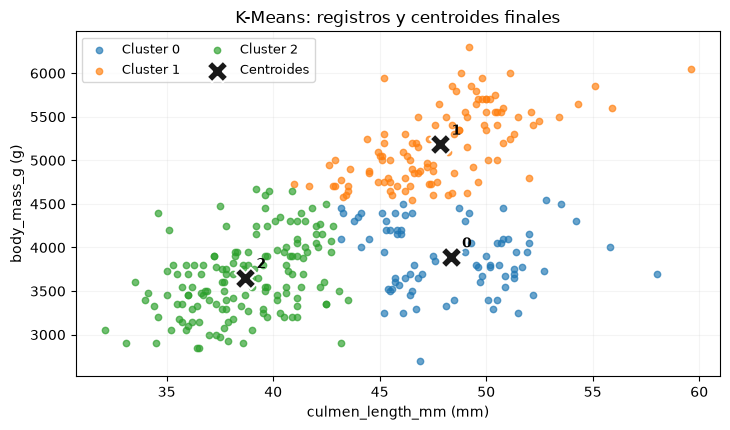

,K,Silhouette
0,3,0.467


Cluster,0,1,2
Especie real,,,
Adelie,5,4,142
Chinstrap,61,1,6
Gentoo,15,105,3


In [7]:
silueta = silhouette_score(X_escalado, grupos)
centros_originales = escalador.inverse_transform(modelo.cluster_centers_)

apoyo_visual.mostrar_clusters(X, grupos, centros_originales, columnas)
display(pd.DataFrame({"K": [k], "Silhouette": [round(silueta, 3)]}))
display(pd.crosstab(preparados["species"], grupos, rownames=["Especie real"], colnames=["Cluster"]))

### Preguntas A · K-Means

**A1.** ¿Qué es el **dominio de entrada** de K-Means? Identifique `X` y explique por qué no se utilizó `species` para entrenar.

*Respuesta:* El dominio de entrada es el conjunto de datos numéricos con los que K-Means mide distancias. Aquí `X` son dos columnas: `culmen_length_mm` y `body_mass_g` (342 pingüinos). `species` no se usó para entrenar porque K-Means es no supervisado: no recibe respuestas (`y`); la especie se reserva solo para interpretar los grupos después.

**A2.** ¿Qué ocurre con los `NaN` y cómo cambia el conjunto entre eliminarlos o rellenarlos? ¿Por qué también fue necesario escalar?

*Respuesta:* K-Means no acepta `NaN`. Con "eliminar" se pasa de 344 a 342 registros (se pierden 2 filas completamente vacías, poco relevante); con "mediana" se conservan los 344, pero se inventan dos pingüinos con valores medianos. Los resultados casi no cambian (Silhouette 0,467 vs 0,464 con k=3). Escalar fue necesario porque el pico (≈40–60 mm) y la masa (≈3000–6000 g) están en escalas muy distintas y la masa dominaría las distancias.

**A3.** Explique cómo se asignan registros y se mueven los centroides. Repita el entrenamiento con `k=5`: ¿qué cambió respecto de `k=3`?

*Respuesta:* En cada iteración cada punto se asigna al centroide más cercano y luego cada centroide se recalcula como el promedio de su grupo, hasta estabilizarse. Con k=5 los grupos se subdividen en partes más pequeñas (por ejemplo, Adelie queda repartido en dos o tres clusters) y el Silhouette baja de 0,467 a 0,410: hay más solapamiento entre grupos vecinos.

**A4.** ¿Qué dicen Silhouette y la tabla especies–clusters? ¿Tener tres grupos implica haber identificado las tres especies?

*Respuesta:* Silhouette = 0,467 indica una separación moderada: hay estructura, pero los grupos se solapan en parte; no es una exactitud de clasificación. En la tabla, el cluster 2 reúne a casi todos los Adelie (142), el 1 a casi todos los Gentoo (105) y el 0 a la mayoría de los Chinstrap (61), pero con mezclas (p. ej., 15 Gentoo y 5 Adelie en el cluster 0). Tener tres grupos no implica haber identificado las tres especies: los clusters son grupos de medidas parecidas, no especies, y el modelo nunca vio la etiqueta.

## B. Aprendizaje por refuerzo · Aprender mediante decisiones

En **CartPole** un carro debe mover una barra para que no caiga. En lugar de recibir un CSV con respuestas correctas, el **agente** observa un **estado**, ejecuta una **acción** en el **entorno**, recibe una **recompensa** y observa el nuevo estado.

**Ciclo:** estado → política elige acción → entorno reacciona → nuevo estado + recompensa → nueva decisión.

El agente aprende una **política** (estrategia para elegir acciones), no un cluster. Aquí utilizaremos **PPO** (*Proximal Policy Optimization*).

In [8]:
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

nombre_entorno = "CartPole-v1"
entorno = gym.make(nombre_entorno)

# Espacios permitidos por el entorno.
display(pd.DataFrame({"Observaciones": [str(entorno.observation_space)],
                      "Acciones": [str(entorno.action_space)]}))

,Observaciones,Acciones
0,Box([-4.8 -inf -0.41887903 ...,Discrete(2)


### B1. Estado, acción, paso y episodio

El **estado** contiene cuatro números: posición y velocidad del carro, ángulo y velocidad angular de la barra. El agente elige `0` (izquierda) o `1` (derecha).

Un **paso** (`step`) es una acción y su consecuencia. Varios pasos forman un **episodio**, que termina cuando cae la barra, el carro se sale o llega al límite de **500 pasos**.

Aquí el entorno otorga **+1 por cada paso**, incluido el último; si el episodio dura 120 pasos, su recompensa total es 120. No equivale a 120 % de precisión. `reset()` empieza un episodio y `step(accion)` devuelve el nuevo estado, recompensa y señales de finalización.

In [9]:
estado, _ = entorno.reset(seed=17)
accion = 1  # se probó 0 (izquierda) y luego 1 (derecha)
nuevo_estado, recompensa, terminado, truncado, _ = entorno.step(accion)

display(pd.DataFrame({"Acción": [accion],
                      "Ángulo previo (°)": [round(float(np.degrees(estado[2])), 2)],
                      "Ángulo nuevo (°)": [round(float(np.degrees(nuevo_estado[2])), 2)],
                      "Recompensa": [recompensa]}))

,Acción,Ángulo previo (°),Ángulo nuevo (°),Recompensa
0,1,0.33,0.32,1.0


### B2. ¿Qué significa entrenar PPO?

PPO utiliza las experiencias del agente para **ajustar una política de decisiones** (en este caso, una red neuronal).

- `total_timesteps`: cantidad aproximada de **interacciones con el entorno** durante `learn()`.
- `n_steps`: pasos de experiencia que PPO **recoge antes de actualizar** su política (por entorno).
- `n_epochs`: veces que PPO **revisa ese lote de experiencias** durante una actualización. **No** es la cantidad de episodios.

Un episodio puede terminar en 15 o en 300 pasos. Un entrenamiento contiene muchos episodios y actualizaciones.

In [10]:
epocas_por_actualizacion = 5
agente = PPO("MlpPolicy", entorno, n_steps=512, batch_size=64,
             n_epochs=epocas_por_actualizacion, verbose=0,
             seed=42, device="cpu")
pesos_inicio = apoyo_visual.guardar_politica(agente)

### B3. Evaluar antes de entrenar

`evaluate_policy(modelo, entorno, n_eval_episodes=N, deterministic=True)` ejecuta **N episodios** y devuelve **media y desviación** de sus recompensas.

Ejemplo: si tres episodios entregan **20, 40 y 60**, la recompensa media es **40**. Un episodio aislado no representa necesariamente el rendimiento general. Una política sin entrenamiento puede equilibrar la barra durante algunos pasos por casualidad.

In [11]:
episodios_evaluacion = 5
entorno_evaluacion = Monitor(gym.make(nombre_entorno))
media_inicio, desv_inicio = evaluate_policy(
    agente, entorno_evaluacion,
    n_eval_episodes=episodios_evaluacion, deterministic=True
)
display(pd.DataFrame({"Etapa": ["Antes"], "Media": [round(media_inicio, 1)],
                      "Desviación": [round(desv_inicio, 1)]}))

,Etapa,Media,Desviación
0,Antes,112.6,22.2


### B4. Entrenar en dos etapas y seguir aprendiendo

`learn(total_timesteps=N)` provoca aproximadamente **N interacciones** y actualiza la política. Primero entrenaremos 4.096 pasos y después **continuaremos** otros 8.192 con `reset_num_timesteps=False`: no se parte de cero.

Guardaremos el estado de la política tras cada etapa para visualizarla después. El resultado puede fluctuar; la recompensa media de varios episodios importa más que un único recorrido.

In [12]:
pasos_primera_etapa = 4096
agente.learn(total_timesteps=pasos_primera_etapa, reset_num_timesteps=False)
pesos_mitad = apoyo_visual.guardar_politica(agente)
media_mitad, desv_mitad = evaluate_policy(
    agente, entorno_evaluacion,
    n_eval_episodes=episodios_evaluacion, deterministic=True
)
display(pd.DataFrame({"Etapa": ["Parcial"], "Media": [round(media_mitad, 1)],
                      "Desviación": [round(desv_mitad, 1)]}))

,Etapa,Media,Desviación
0,Parcial,129.0,51.5


In [13]:
pasos_segunda_etapa = 8192
agente.learn(total_timesteps=pasos_segunda_etapa, reset_num_timesteps=False)
pesos_final = apoyo_visual.guardar_politica(agente)
media_final, desv_final = evaluate_policy(
    agente, entorno_evaluacion,
    n_eval_episodes=episodios_evaluacion, deterministic=True
)
resumen = pd.DataFrame({"Etapa": ["Antes", "Parcial", "Final"],
                        "Media": [media_inicio, media_mitad, media_final],
                        "Desviación": [desv_inicio, desv_mitad, desv_final]})
display(resumen.round(1))

,Etapa,Media,Desviación
0,Antes,112.6,22.2
1,Parcial,129.0,51.5
2,Final,495.2,9.6


In [14]:
# predict(estado) elige una acción sin reentrenar la política.
estado, _ = entorno.reset(seed=17)
determinista = True
accion, _ = agente.predict(estado, deterministic=determinista)
estado_nuevo, recompensa, terminado, truncado, _ = entorno.step(int(accion))
display(pd.DataFrame({"Acción": [int(accion)], "Recompensa": [recompensa],
                      "Ángulo nuevo (°)": [round(float(np.degrees(estado_nuevo[2])), 2)]}))

,Acción,Recompensa,Ángulo nuevo (°)
0,0,1.0,0.32


### B5. Explorar el comportamiento a distintas etapas

Esta visualización **sí utiliza las políticas guardadas** en tres momentos reales del entrenamiento. Elija **Antes**, **Parcial** o **Final**, cambie **Caso inicial** y mueva **Paso** para observar el carro, la barra, la acción y la recompensa acumulada.

Se reproduce **un episodio bajo la misma condición inicial** para cada etapa. La tabla anterior resume **varios episodios** y es la referencia más confiable para evaluar el modelo.

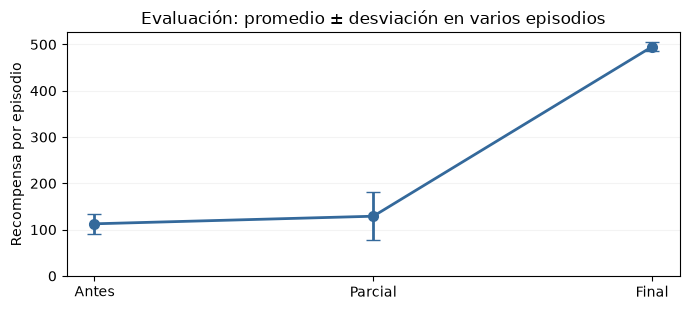

In [15]:
apoyo_visual.grafico_recompensas(resumen)
apoyo_visual.explorar_cartpole(agente, {
    "Antes de entrenar": pesos_inicio,
    "Entrenamiento parcial": pesos_mitad,
    "Entrenamiento final": pesos_final
})

### Preguntas B · Aprendizaje por refuerzo

**B1.** Identifique agente, entorno, estado, acciones y recompensa de CartPole. ¿Quién define las recompensas y qué significa obtener 120 puntos?

*Respuesta:* Agente: el controlador PPO que mueve el carro. Entorno: CartPole-v1 (carro + barra con su física). Estado: 4 números (posición y velocidad del carro, ángulo y velocidad angular de la barra). Acciones: 0 (izquierda) o 1 (derecha). Recompensa: +1 por cada paso, definida por el entorno (por su diseñador, no por el agente). 120 puntos significa que la barra se mantuvo 120 pasos antes de que terminara el episodio; no es un 120 % de precisión.

**B2.** Diferencie **paso**, **episodio**, `total_timesteps` y `n_epochs`. ¿Qué hace PPO y qué aprende su política?

*Respuesta:* Un paso es una acción y su consecuencia; un episodio es la secuencia de pasos hasta que cae la barra, el carro sale o se llega a 500 pasos. `total_timesteps` es el total aproximado de interacciones con el entorno durante `learn()` (incluye muchos episodios) y `n_epochs` es cuántas pasadas de optimización se dan sobre el lote recogido en cada actualización, no un número de episodios. PPO usa la experiencia para ajustar una política (red neuronal) que, dado un estado, elige acciones que acumulen más recompensa.

**B3.** Compare las etapas inicial, parcial y final. ¿Qué significa la **recompensa media**? ¿Por qué una sola animación no demuestra que un modelo haya mejorado?

*Respuesta:* En esta ejecución, con 5 episodios: antes 126,4 ± 29,6; parcial 121,6 ± 73,4; final 387,8 ± 117,8. Hay una mejora clara solo al final; en la etapa parcial no mejoró (y fue más inestable). La recompensa media es el promedio de varios episodios independientes. Una sola animación no demuestra mejora porque un episodio puede salir bien o mal por azar (la desviación es alta) y depende de la condición inicial; además una política sin entrenar también puede aguantar bastantes pasos por casualidad.

## C. Integración · Comparar paradigmas de Machine Learning

**C1. Dominio de los modelos.** ¿Qué tipo de información necesita una regresión lineal, un clasificador supervisado, K-Means y PPO? ¿Qué diferencia hay entre datos de entrada, etiquetas y recompensas?

*Respuesta:* Regresión lineal: datos de entrada `X` y una etiqueta numérica `y` (supervisado). Clasificador: `X` y una etiqueta de categoría. K-Means: solo `X`, sin etiquetas. PPO: no recibe un dataset; recibe estados, acciones y recompensas al interactuar con un entorno. Los datos de entrada describen cada caso, las etiquetas son la respuesta correcta que se quiere aprender y las recompensas son una señal de qué tan buena fue una acción, sin decir cuál era la correcta.

**C2. Flujo.** Compare **analizar → preparar → entrenar → predecir o actuar → evaluar** para regresión/clasificación, K-Means y PPO. ¿De dónde vienen sus datos de entrenamiento y cuál es su salida?

*Respuesta:* Todos siguen analizar → preparar → entrenar → predecir/actuar → evaluar. En regresión/clasificación los datos vienen de una tabla etiquetada, se entrena con `fit(X, y)` y la salida es un número o una clase, evaluada con MAE/R² o exactitud. En K-Means los datos son una tabla sin etiquetas, la salida es el cluster de cada registro y se evalúa con Silhouette. En PPO los datos se generan al interactuar con el entorno, la salida es una acción y se evalúa con la recompensa media por episodio.

**C3. Aplicaciones.** Proponga un caso real para **regresión, clasificación, clustering y aprendizaje por refuerzo**. Justifique qué datos necesita y por qué elegiría ese enfoque.

*Respuesta:* Regresión: predecir el precio de una vivienda a partir de su superficie y ubicación (datos históricos con precio). Clasificación: detectar correos spam (correos etiquetados como spam/no spam). Clustering: segmentar clientes de una tienda según sus compras, sin grupos predefinidos. Refuerzo: controlar un robot o el semáforo de un cruce, donde no hay respuestas correctas y se aprende por prueba y error con una recompensa.

**C4. Relación entre enfoques.** ¿Podrían combinarse dos enfoques en una misma aplicación? Describa un ejemplo y qué función cumple cada uno.

*Respuesta:* Sí. Por ejemplo, en un sistema de recomendación o de gestión de energía: clustering para agrupar usuarios según su comportamiento, regresión para predecir la demanda de cada grupo y refuerzo para decidir qué acción tomar (qué recomendar o cuánta energía asignar) maximizando una recompensa a largo plazo. Cada enfoque cumple una función distinta: descubrir grupos, predecir y decidir.

---

**Entrega:** responda brevemente (2 a 4 líneas por pregunta). Conserve los gráficos. Un notebook ejecutado, con sus gráficos, resultados y respuestas. No se evalúa memorizar código; se evalúa comprender el proceso y justificar decisiones.